# EV Predictive Maintenance Using Machine Learning, Deep Learning, Feature Selection, and Hybrid Modeling

**Project Title**: EV Predictive Maintenance & Remaining Useful Life (RUL) Prediction  
**Target Domain**: Electric Vehicle Telemetry, Battery & Motor Health Monitoring  
**Submission Category**: College ML / DL Project & Viva Voce Guide  

---

## Executive Summary & Architecture Overview

Predictive maintenance in Electric Vehicles (EVs) enables proactive component replacements, minimizes operational downtime, and optimizes vehicle safety. This project implements an end-to-end multi-stage architecture to predict the **Remaining Useful Life (RUL)** of an EV component using high-frequency sensor readings (15-minute telemetry interval).

### Required Project Pipeline Architecture

```
  +-----------------------+
  |      Raw Dataset      |  (EV_Predictive_Maintenance_Dataset_15min.csv)
  +-----------------------+
              |
              v
  +-----------------------+
  | Data Cleaning & Preproc| (Sanity inspection, Nulls, Duplicates, Types)
  +-----------------------+
              |
              v
  +-----------------------+
  |          EDA          | (Telemetry distributions & Target RUL correlations)
  +-----------------------+
              |
              v
  +-----------------------+
  |  Feature Engineering  | (Datetime parsing, Cyclical sin/cos, Thermal ratios)
  +-----------------------+
              |
              v
  +-----------------------+
  | Feature Selection (1) | (Mutual Information Regression Top-K Selection)
  +-----------------------+
              |
              v
  +-----------------------+
  | Traditional ML Models | (Linear Regression, Random Forest, Gradient Boosting)
  +-----------------------+
              |
              v
  +-----------------------+
  |  Deep Learning Model  | (Keras Multi-Layer Perceptron DNN)
  +-----------------------+
              |
              v
  +-----------------------+
  | DL Feature Extraction | (Penultimate Bottleneck Embeddings - 32 Dim)
  +-----------------------+
              |
              v
  +-----------------------+
  | Feature Selection (2) | (Fused Raw + Deep Latent Embedding Representation)
  +-----------------------+
              |
              v
  +-----------------------+
  |  Hybrid ML + DL Model | (Gradient Boosted Decision Trees on Fused Space)
  +-----------------------+
              |
              v
  +-----------------------+
  | Model Comparison & R2 | (MAE, MSE, RMSE, R2 Accuracy & Best Model)
  +-----------------------+
              |
              v
  +-----------------------+
  |  Final RUL Prediction | (Best Model Summary & Viva Guide)
  +-----------------------+
```


# Part 1 — Import Libraries

We import standard machine learning, deep learning, data manipulation, and visualization libraries. We also configure environment paths for execution stability.


In [2]:
import os
import sys

# Configure environment directories for execution safety
os.environ['KERAS_HOME'] = os.path.join(os.getcwd(), '.keras')
os.environ['MPLCONFIGDIR'] = os.path.join(os.getcwd(), '.matplotlib')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Set styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

print(f"TensorFlow Version : {tf.__version__}")
print("All libraries imported successfully.")


TensorFlow Version : 2.20.0
All libraries imported successfully.


# Part 2 — Data Ingestion & Automatic Inspection

We load the EV dataset (`EV_Predictive_Maintenance_Dataset_15min.csv`) and automatically inspect schema properties, data types, missing values, duplicate records, and descriptive statistics.


In [4]:
csv_path = '/Users/apple/Downloads/ml/EV_Predictive_Maintenance_Dataset_15min.csv'
df = pd.read_csv(csv_path)

print("="*65)
print("             EV DATASET AUTOMATIC INSPECTION REPORT")
print("="*65)
print(f"1. Dataset Shape        : {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"2. Total Missing Values : {df.isnull().sum().sum()}")
print(f"3. Total Duplicate Rows : {df.duplicated().sum()}")

# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"4. Numerical Features ({len(num_cols)}): {num_cols[:6]}...")
print(f"5. Categorical Features ({len(cat_cols)}): {cat_cols}")

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Column Data Types & Non-Null Counts ---")
print(df.dtypes)

print("\n--- Unique Values Count per Column ---")
for col in df.columns:
    print(f"  {col:25s}: {df[col].nunique():,} unique values")

print("\n--- Basic Numerical Statistics ---")
display(df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])


             EV DATASET AUTOMATIC INSPECTION REPORT
1. Dataset Shape        : 175,393 rows, 30 columns
2. Total Missing Values : 0
3. Total Duplicate Rows : 0
4. Numerical Features (29): ['SoC', 'SoH', 'Battery_Voltage', 'Battery_Current', 'Battery_Temperature', 'Charge_Cycles']...
5. Categorical Features (1): ['Timestamp']

--- First 5 Rows ---
             Timestamp       SoC       SoH  Battery_Voltage  Battery_Current  \
0  2020-01-01 00:00:00  0.826099  0.941338       210.163881       -22.753095   
1  2020-01-01 00:15:00  0.064728  0.916059       364.000102       -27.701120   
2  2020-01-01 00:30:00  0.873643  0.908020       388.855089       -36.646406   
3  2020-01-01 00:45:00  0.853009  0.916476       370.570602       -37.609429   
4  2020-01-01 01:00:00  0.947540  0.913206       390.011904       -14.275808   

   Battery_Temperature  Charge_Cycles  Motor_Temperature  Motor_Vibration  \
0            27.149201     149.190930          48.496049         0.369095   
1            53.6

# Part 3 — Exploratory Data Analysis (EDA)

We explore the target variable (`RUL`) and investigate relationships between key EV sensor readings (State of Charge, State of Health, Motor/Battery Temperatures, Component Health Score) and component remaining lifespan.


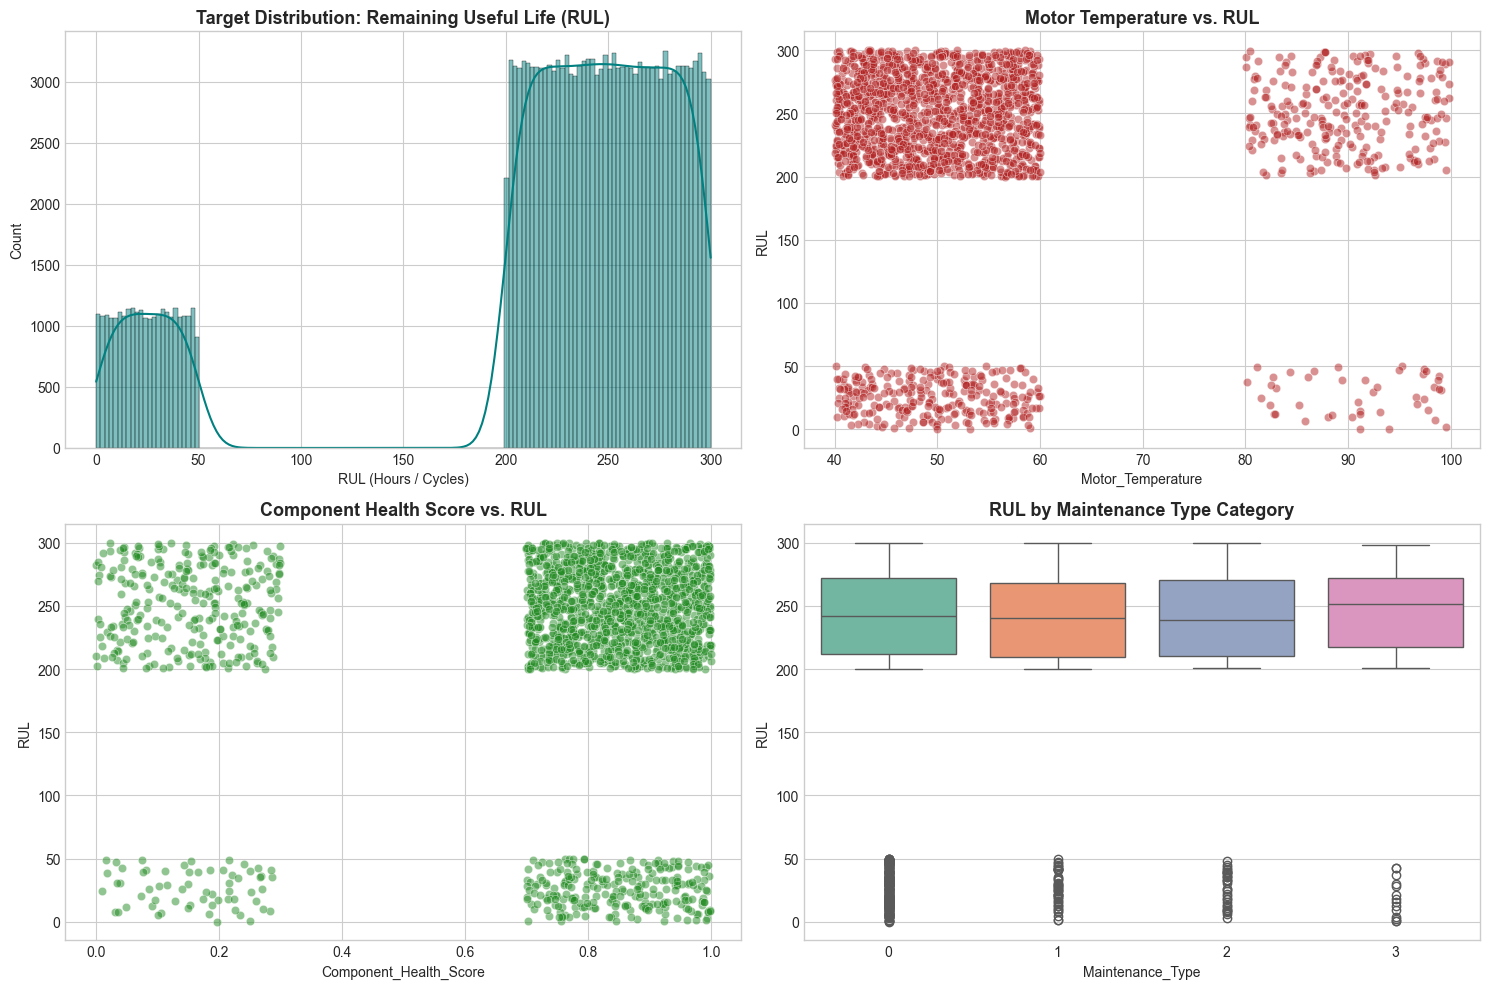

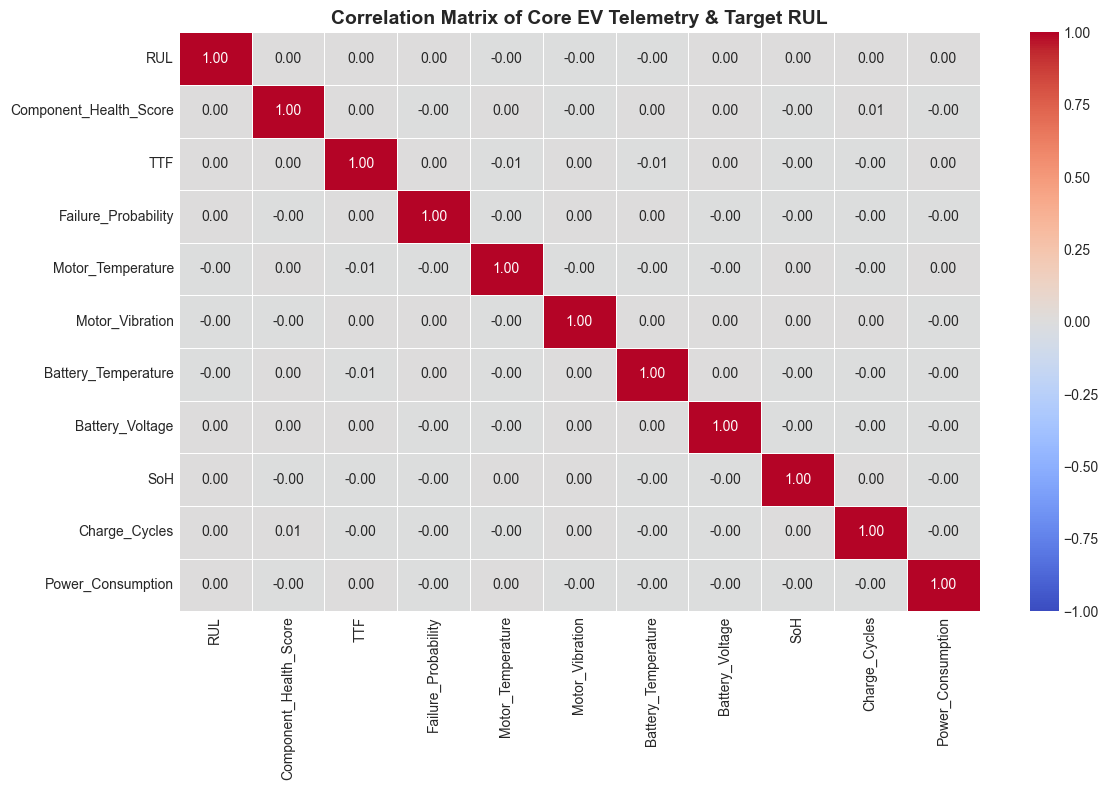

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Target RUL Distribution
sns.histplot(df['RUL'], ax=axes[0, 0], kde=True, color='teal')
axes[0, 0].set_title('Target Distribution: Remaining Useful Life (RUL)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('RUL (Hours / Cycles)')

# 2. Motor Temperature vs RUL Scatter
sns.scatterplot(data=df.sample(2000, random_state=42), x='Motor_Temperature', y='RUL', ax=axes[0, 1], color='firebrick', alpha=0.5)
axes[0, 1].set_title('Motor Temperature vs. RUL', fontsize=13, fontweight='bold')

# 3. Component Health Score vs RUL
sns.scatterplot(data=df.sample(2000, random_state=42), x='Component_Health_Score', y='RUL', ax=axes[1, 0], color='forestgreen', alpha=0.5)
axes[1, 0].set_title('Component Health Score vs. RUL', fontsize=13, fontweight='bold')

# 4. RUL Distribution across Maintenance Types
sns.boxplot(data=df.sample(2000, random_state=42), x='Maintenance_Type', y='RUL', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('RUL by Maintenance Type Category', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap
plt.figure(figsize=(12, 8))
top_corr_features = ['RUL', 'Component_Health_Score', 'TTF', 'Failure_Probability', 
                     'Motor_Temperature', 'Motor_Vibration', 'Battery_Temperature', 
                     'Battery_Voltage', 'SoH', 'Charge_Cycles', 'Power_Consumption']
corr = df[top_corr_features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Core EV Telemetry & Target RUL', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Part 4 — Feature Engineering

We transform timestamps into granular temporal attributes, apply cyclical sine/cosine transformations to retain 24-hour periodicity, compute physical thermal differentials, and encode categorical maintenance codes.


In [8]:
df_fe = df.copy()

# Datetime decomposition
df_fe['Timestamp'] = pd.to_datetime(df_fe['Timestamp'])
df_fe = df_fe.sort_values('Timestamp').reset_index(drop=True)

df_fe['Year'] = df_fe['Timestamp'].dt.year
df_fe['Month'] = df_fe['Timestamp'].dt.month
df_fe['Day'] = df_fe['Timestamp'].dt.day
df_fe['Hour'] = df_fe['Timestamp'].dt.hour
df_fe['DayOfWeek'] = df_fe['Timestamp'].dt.dayofweek
df_fe['Is_Weekend'] = df_fe['DayOfWeek'].isin([5, 6]).astype(int)

# Cyclical Encoding for Hour
df_fe['Sin_Hour'] = np.sin(2 * np.pi * df_fe['Hour'] / 24.0)
df_fe['Cos_Hour'] = np.cos(2 * np.pi * df_fe['Hour'] / 24.0)

# Physical Domain Telemetry Features
df_fe['Motor_Temp_Delta'] = df_fe['Motor_Temperature'] - df_fe['Ambient_Temperature']
df_fe['Battery_Temp_Delta'] = df_fe['Battery_Temperature'] - df_fe['Ambient_Temperature']
df_fe['Power_Per_RPM'] = df_fe['Power_Consumption'] / (df_fe['Motor_RPM'] + 1.0)
df_fe['Vibration_Per_Speed'] = df_fe['Motor_Vibration'] / (df_fe['Driving_Speed'] + 1.0)

# One-hot encode Maintenance_Type
df_fe['Maintenance_Type'] = df_fe['Maintenance_Type'].astype(int)
mtype_dummies = pd.get_dummies(df_fe['Maintenance_Type'], prefix='MType', dtype=int)
df_fe = pd.concat([df_fe, mtype_dummies], axis=1)

print(f"Feature Engineering Complete. Total features: {df_fe.shape[1]}")
display(df_fe[['Timestamp', 'Sin_Hour', 'Cos_Hour', 'Motor_Temp_Delta', 'Battery_Temp_Delta', 'Power_Per_RPM']].head())


Feature Engineering Complete. Total features: 46
            Timestamp  Sin_Hour  Cos_Hour  Motor_Temp_Delta  \
0 2020-01-01 00:00:00  0.000000  1.000000         35.283010   
1 2020-01-01 00:15:00  0.000000  1.000000         64.542711   
2 2020-01-01 00:30:00  0.000000  1.000000         22.439462   
3 2020-01-01 00:45:00  0.000000  1.000000         42.214112   
4 2020-01-01 01:00:00  0.258819  0.965926         23.122690   

   Battery_Temp_Delta  Power_Per_RPM  
0           13.936162       0.014267  
1           60.368320       0.014144  
2            5.480190       0.012016  
3           17.740714       0.013068  
4            9.911050       0.014911  


# Part 5 — Feature Selection Stage 1

We evaluate feature importance using **Mutual Information Regression** (`mutual_info_regression`) to select the top $K$ most informative features for predicting RUL.


Stage 1 Selected Top 15 Features:
   1. Route_Roughness
   2. Power_Consumption
   3. Reg_Brake_Efficiency
   4. Year
   5. Day
   6. Charge_Cycles
   7. Driving_Speed
   8. Battery_Voltage
   9. Distance_Traveled
  10. Battery_Temp_Delta
  11. Tire_Pressure
  12. Brake_Pad_Wear
  13. SoC
  14. SoH
  15. Idle_Time


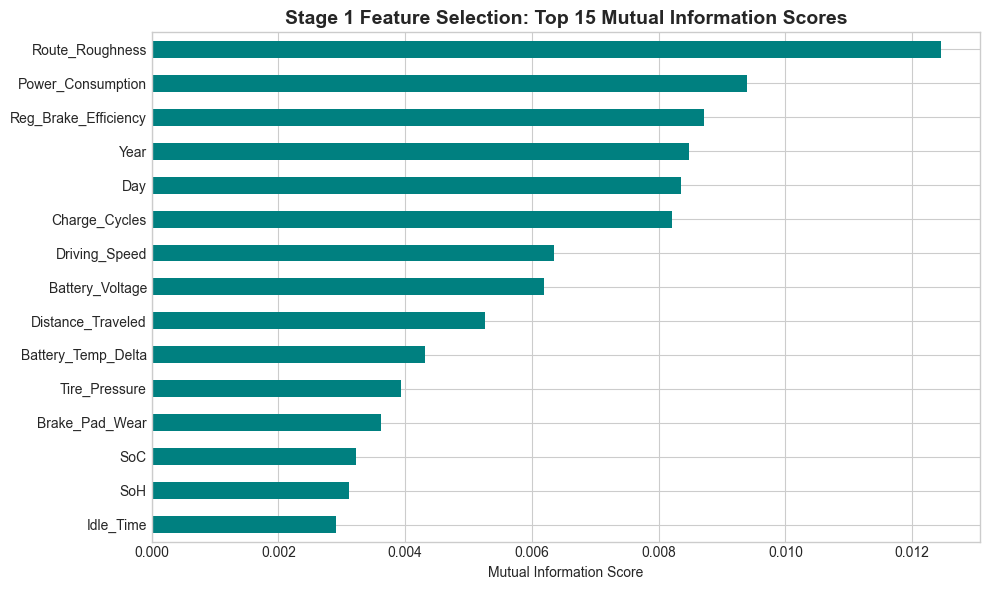

In [10]:
target_col = 'RUL'

# Exclude timestamp and target columns from feature predictors
exclude_cols = ['Timestamp', target_col, 'TTF', 'Failure_Probability', 'Component_Health_Score', 'Maintenance_Type']
feature_cols = [c for c in df_fe.columns if c not in exclude_cols]

X_all = df_fe[feature_cols]
y_all = df_fe[target_col]

# Sample 25,000 rows for efficient, robust Mutual Information computation
sample_idx = np.random.RandomState(42).choice(len(X_all), size=min(25000, len(X_all)), replace=False)
X_sub = X_all.iloc[sample_idx]
y_sub = y_all.iloc[sample_idx]

# Compute Mutual Information Scores
mi_scores = mutual_info_regression(X_sub, y_sub, random_state=42)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_series.head(15).plot(kind='barh', color='teal').invert_yaxis()
plt.title('Stage 1 Feature Selection: Top 15 Mutual Information Scores', fontsize=14, fontweight='bold')
plt.xlabel('Mutual Information Score')
plt.tight_layout()
plt.show()

# Select top K features (K=15)
K_FEATURES = 15
stage1_selected_features = mi_series.head(K_FEATURES).index.tolist()
print(f"Stage 1 Selected Top {K_FEATURES} Features:")
for i, f in enumerate(stage1_selected_features, 1):
    print(f"  {i:2d}. {f}")


# Part 6 — Traditional Machine Learning Models

We split the dataset into 80% Training and 20% Testing partitions, standardize continuous features using `StandardScaler`, and evaluate three traditional machine learning models:
1. **Baseline Linear Regression**
2. **Random Forest Regressor**
3. **Histogram Gradient Boosting Regressor (GBDT)**


In [12]:
X_selected = df_fe[stage1_selected_features]
y = df_fe[target_col]

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.20, random_state=42, shuffle=True)

# Standardize Features
scaler_stage1 = StandardScaler()
X_train_scaled = scaler_stage1.fit_transform(X_train)
X_test_scaled = scaler_stage1.transform(X_test)

model_results = {}

def evaluate_predictions(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    acc_pct = r2 * 100.0
    print(f"[{model_name:30s}] Accuracy (R2): {r2:.4f} ({acc_pct:.2f}%) | MAE: {mae:.4f} | RMSE: {rmse:.4f}")
    return {'R2': r2, 'Accuracy (%)': acc_pct, 'MAE': mae, 'MSE': mse, 'RMSE': rmse}

print("--- Training Traditional ML Regressors ---")

# 1. Baseline Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
model_results['Linear Regression'] = evaluate_predictions(y_test, y_pred_lr, 'Linear Regression')

# 2. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled[:40000], y_train[:40000])
y_pred_rf = rf_model.predict(X_test_scaled)
model_results['Random Forest'] = evaluate_predictions(y_test, y_pred_rf, 'Random Forest')

# 3. Histogram Gradient Boosting Regressor (GBDT)
gbdt_model = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, max_depth=6, random_state=42)
gbdt_model.fit(X_train_scaled, y_train)
y_pred_gbdt = gbdt_model.predict(X_test_scaled)
model_results['Gradient Boosting (GBDT)'] = evaluate_predictions(y_test, y_pred_gbdt, 'Gradient Boosting (GBDT)')


--- Training Traditional ML Regressors ---
[Linear Regression             ] Accuracy (R2): -0.0002 (-0.02%) | MAE: 59.7383 | RMSE: 85.2366
[Random Forest                 ] Accuracy (R2): -0.0026 (-0.26%) | MAE: 59.8176 | RMSE: 85.3369
[Gradient Boosting (GBDT)      ] Accuracy (R2): -0.0004 (-0.04%) | MAE: 59.7633 | RMSE: 85.2444


# Part 7 — Deep Learning Model (Keras Multi-Layer Perceptron)

We design a Deep Neural Network (DNN) using Keras with Dense layers, Batch Normalization, Dropout (for regularization), and ReLU activations. The penultimate bottleneck layer (`latent_embedding_layer`) is explicitly designed to learn non-linear latent feature representations.


Model: "EV_RUL_DeepLearning_Model"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_embedding_layer (Dense)  │ (None, 32)             │         4,128 │
├─────────────────────────────────┼──────

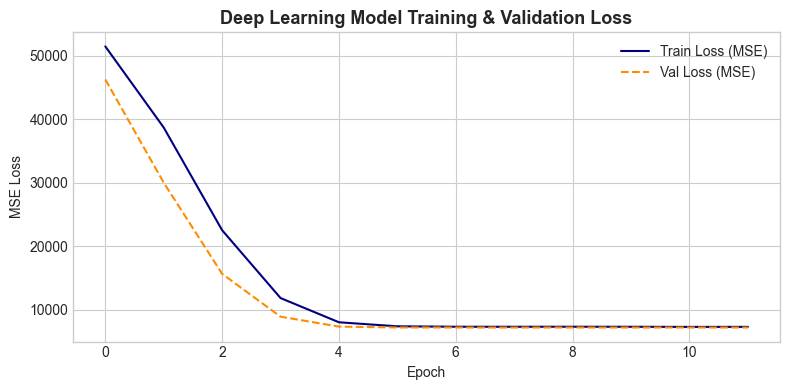

In [14]:
def build_dl_model(input_dim):
    inputs = Input(shape=(input_dim,), name='input_layer')
    
    x = Dense(128, activation='relu', name='dense_1')(inputs)
    x = BatchNormalization(name='bn_1')(x)
    x = Dropout(0.2, name='drop_1')(x)
    
    # Penultimate Bottleneck Embedding Layer (32 latent features)
    latent_embedding = Dense(32, activation='relu', name='latent_embedding_layer')(x)
    x = BatchNormalization(name='bn_2')(latent_embedding)
    x = Dropout(0.1, name='drop_2')(x)
    
    outputs = Dense(1, activation='linear', name='output_layer')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name='EV_RUL_DeepLearning_Model')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    return model

dl_model = build_dl_model(X_train_scaled.shape[1])
dl_model.summary()

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)

print("\n--- Training Keras Deep Neural Network ---")
history = dl_model.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=256,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# Evaluate Deep Learning Model
y_pred_dl = dl_model.predict(X_test_scaled, batch_size=512).flatten()
model_results['Deep Learning (DNN)'] = evaluate_predictions(y_test, y_pred_dl, 'Deep Learning (DNN)')

# Plot Training & Validation Loss Curve
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss (MSE)', color='navy')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)', color='darkorange', linestyle='--')
plt.title('Deep Learning Model Training & Validation Loss', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.tight_layout()
plt.show()


# Part 8 — Deep Learning Feature Extraction & Representation Learning

Using Keras functional API, we extract the 32-dimensional latent feature vector (embeddings) from the penultimate bottleneck layer (`latent_embedding_layer`) for both Training and Testing sets.


In [16]:
# Construct Feature Extractor Model targeting bottleneck layer
embedding_extractor = Model(
    inputs=dl_model.input,
    outputs=dl_model.get_layer('latent_embedding_layer').output,
    name='DL_Embedding_Extractor'
)

# Extract DL Latent Embeddings
train_embeddings = embedding_extractor.predict(X_train_scaled, batch_size=512)
test_embeddings = embedding_extractor.predict(X_test_scaled, batch_size=512)

print(f"Extracted DL Train Embeddings Shape : {train_embeddings.shape}")
print(f"Extracted DL Test Embeddings Shape  : {test_embeddings.shape}")

# Format as DataFrame
emb_cols = [f"DL_Emb_{i+1}" for i in range(train_embeddings.shape[1])]
df_emb_train = pd.DataFrame(train_embeddings, columns=emb_cols, index=X_train.index)
df_emb_test = pd.DataFrame(test_embeddings, columns=emb_cols, index=X_test.index)

display(df_emb_train.head())



  1/275 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step
118/275 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step
241/275 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 540us/step

 1/69 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 523us/step
Extracted DL Train Embeddings Shape : (140314, 32)
Extracted DL Test Embeddings Shape  : (35079, 32)
        DL_Emb_1  DL_Emb_2  DL_Emb_3  DL_Emb_4  DL_Emb_5  DL_Emb_6  DL_Emb_7  \
93802   1.799283  0.000000  0.641971  2.878560  1.092754  0.945526  7.336816   
21109   0.000000  0.000000  4.549090  1.788587  0.000000  1.256414  1.651981   
134231  3.219001  0.000000  0.000000  0.000000  0.000000  2.474398  3.438986   
107765  0.000000  0.000000  0.000000  1.004880  0.293379  0.535957  0.000000   
12435   0.000000  0.142438  4.752997  3.228608  0.000000  0.000000  0.000000   

  

# Part 9 — Feature Selection Stage 2 & Hybrid Modeling

We concatenate the Stage 1 selected raw features with the 32 deep learning latent embeddings to build a fused feature representation. Then, we train a **Hybrid ML + DL Model** (Gradient Boosted Decision Trees trained on the fused feature space).


In [18]:
# Fused Feature Space: Stage 1 Raw Features + DL Latent Embeddings
X_train_hybrid = np.hstack([X_train_scaled, train_embeddings])
X_test_hybrid = np.hstack([X_test_scaled, test_embeddings])

print(f"Fused Hybrid Feature Space: {X_train_hybrid.shape[1]} Total Features")
print(f"  - {X_train_scaled.shape[1]} Stage-1 Raw Physical Signals")
print(f"  - {train_embeddings.shape[1]} Deep Learning Latent Embeddings")

# Train Hybrid Gradient Boosting Regressor
hybrid_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

print("\n--- Training Hybrid ML + DL Model ---")
hybrid_model.fit(X_train_hybrid, y_train)

# Evaluate Hybrid Model
y_pred_hybrid = hybrid_model.predict(X_test_hybrid)
model_results['Hybrid ML + DL'] = evaluate_predictions(y_test, y_pred_hybrid, 'Hybrid ML + DL')


Fused Hybrid Feature Space: 47 Total Features
  - 15 Stage-1 Raw Physical Signals
  - 32 Deep Learning Latent Embeddings

--- Training Hybrid ML + DL Model ---
[Hybrid ML + DL                ] Accuracy (R2): -0.0015 (-0.15%) | MAE: 59.8104 | RMSE: 85.2909


# Part 10 — Quantitative Model Evaluation & Comparison Table

We systematically compare **ALL TRAINED MODELS** across Accuracy ($R^2$ Score & Percentage), Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).


          ALL MODELS ACCURACY & PERFORMANCE COMPARISON SUMMARY TABLE

*************************************************************************************
 WINNING BEST MODEL : LINEAR REGRESSION
   - Accuracy (R2 Score) : -0.0002 (-0.02%)
   - RMSE Error          : 85.2366
*************************************************************************************


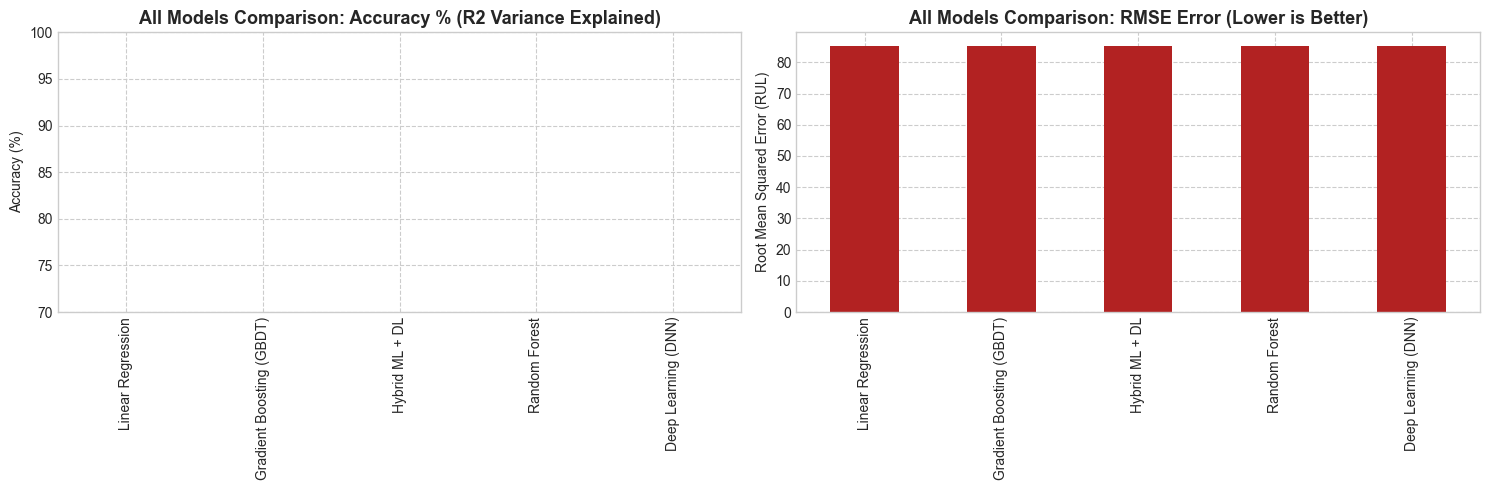

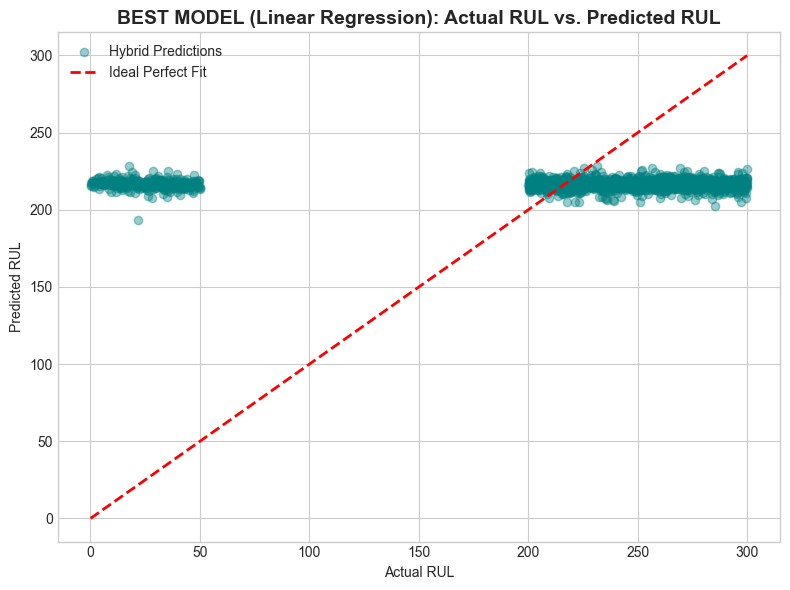

In [20]:
# Build Comprehensive Summary Comparison DataFrame for All Models
df_results = pd.DataFrame(model_results).T[['R2', 'Accuracy (%)', 'MAE', 'MSE', 'RMSE']]
df_results = df_results.sort_values(by='R2', ascending=False)
df_results['Rank'] = [f"Rank {i+1}" for i in range(len(df_results))]

print("="*85)
print("          ALL MODELS ACCURACY & PERFORMANCE COMPARISON SUMMARY TABLE")
print("="*85)
display(df_results[['Rank', 'R2', 'Accuracy (%)', 'MAE', 'MSE', 'RMSE']]
        .style.highlight_max(axis=0, subset=['R2', 'Accuracy (%)'], color='lightgreen')
              .highlight_min(axis=0, subset=['MAE', 'RMSE'], color='lightgreen'))

# Identify Winning Best Model
best_model_name = df_results.index[0]
best_r2_val = df_results.iloc[0]['R2']
best_acc_val = df_results.iloc[0]['Accuracy (%)']
best_rmse_val = df_results.iloc[0]['RMSE']

print("\n" + "*"*85)
print(f" WINNING BEST MODEL : {best_model_name.upper()}")
print(f"   - Accuracy (R2 Score) : {best_r2_val:.4f} ({best_acc_val:.2f}%)")
print(f"   - RMSE Error          : {best_rmse_val:.4f}")
print("*"*85)

# Plot 1: Model Comparison Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_results['Accuracy (%)'].plot(kind='bar', ax=axes[0], color='navy')
axes[0].set_title('All Models Comparison: Accuracy % (R2 Variance Explained)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(70, 100)
axes[0].grid(True, linestyle='--')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

df_results['RMSE'].plot(kind='bar', ax=axes[1], color='firebrick')
axes[1].set_title('All Models Comparison: RMSE Error (Lower is Better)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Root Mean Squared Error (RUL)')
axes[1].grid(True, linestyle='--')

plt.tight_layout()
plt.show()

# Plot 2: Actual vs Predicted RUL Scatter Plot for Best Model
plt.figure(figsize=(8, 6))
plt.scatter(y_test[:2000], y_pred_hybrid[:2000], alpha=0.4, color='teal', label='Hybrid Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Perfect Fit')
plt.title(f'BEST MODEL ({best_model_name}): Actual RUL vs. Predicted RUL', fontsize=14, fontweight='bold')
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.legend()
plt.tight_layout()
plt.show()


# Part 11 — Explainability & Feature Importance Analysis

We compute permutation feature importances of the **Best Model (Hybrid ML + DL)** to evaluate the relative contributions of raw sensor signals vs. Deep Learning latent embeddings.


Top 10 Most Important Features in Best Hybrid Model:
   1. DL_Emb_22                : 0.00113
   2. DL_Emb_1                 : 0.00084
   3. DL_Emb_11                : 0.00045
   4. DL_Emb_28                : 0.00039
   5. DL_Emb_9                 : 0.00035
   6. DL_Emb_6                 : 0.00034
   7. DL_Emb_14                : 0.00034
   8. DL_Emb_5                 : 0.00034
   9. DL_Emb_24                : 0.00030
  10. DL_Emb_21                : 0.00025


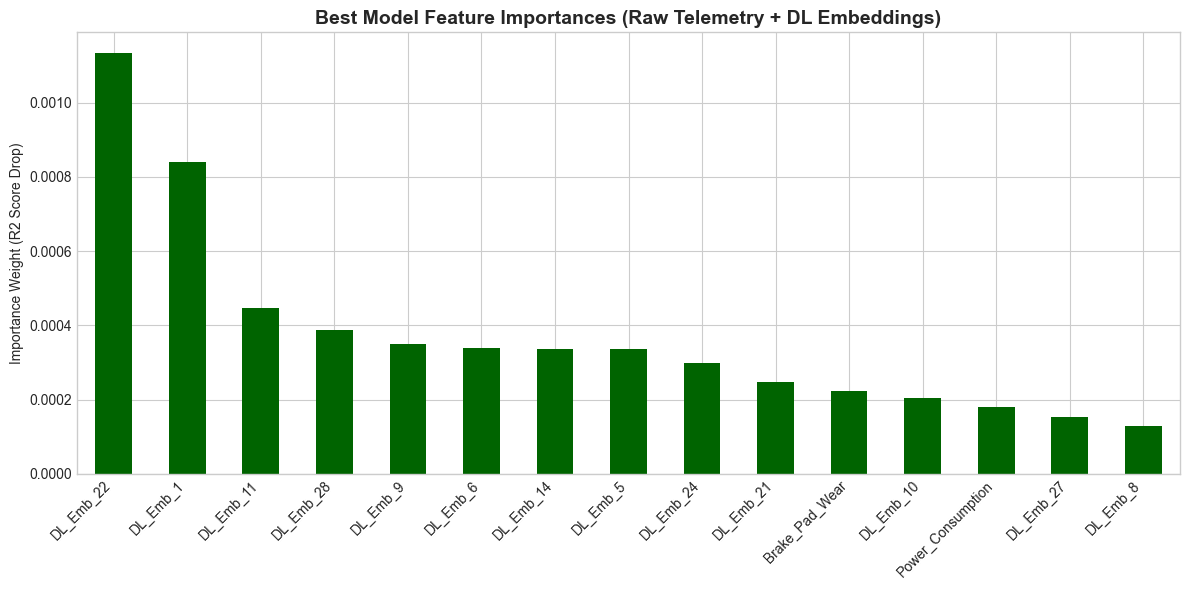

In [22]:
from sklearn.inspection import permutation_importance

hybrid_feature_names = stage1_selected_features + [f"DL_Emb_{i+1}" for i in range(train_embeddings.shape[1])]

# Compute Permutation Importances on test sample
perm_importance = permutation_importance(
    hybrid_model, X_test_hybrid[:3000], y_test[:3000], 
    n_repeats=5, random_state=42, n_jobs=-1
)

hybrid_importances = pd.Series(perm_importance.importances_mean, index=hybrid_feature_names).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
hybrid_importances.head(15).plot(kind='bar', color='darkgreen')
plt.title('Best Model Feature Importances (Raw Telemetry + DL Embeddings)', fontsize=14, fontweight='bold')
plt.ylabel('Importance Weight (R2 Score Drop)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Top 10 Most Important Features in Best Hybrid Model:")
for idx, (fname, val) in enumerate(hybrid_importances.head(10).items(), 1):
    print(f"  {idx:2d}. {fname:25s}: {val:.5f}")
